# Kenyan Food Image Classification

## 1. Introduction

### 1.1 Project Overview

Food recognition through image classification is an application of
machine learning and computer vision that enables computers to
identify food items from digital images.

This project focuses on developing a machine learning model capable
of classifying images of Kenyan foods into 13 different categories.

The project uses supervised learning, specifically multi-class image
classification, to train a Convolutional Neural Network (CNN) to
recognise visual patterns and distinguish between different food
categories.

### 1.2 Problem Statement

Identifying food items from images can be challenging because
different foods may share similar colours, textures and appearances.

The objective of this project is to develop an image classification
system that can automatically identify Kenyan food categories from
input images.

### 1.3 Project Objectives

The main objectives are:

1. Explore and understand the Kenyan food image dataset.
2. Clean and preprocess the images to prepare them for modelling.
3. Develop a Convolutional Neural Network for multi-class
   image classification.
4. Evaluate the model using appropriate classification metrics.
5. Analyse the model's performance and identify areas for improvement.

### 1.4 Machine Learning Approach

This project uses **Supervised Learning** because the training images
are organised into predefined food categories.

The classification task is a **Multi-class Classification Problem**
because each input image is assigned to one of 13 possible categories.

A Convolutional Neural Network (CNN) is used because it can learn
visual features such as edges, shapes, colours and textures from
images.

### 1.5 Expected Output

The expected output is a predicted food category for a given input
image.

The model classifies images into the following 13 categories:

- Bhaji
- Chapati
- Githeri
- Kachumbari
- Kuku Choma
- Mandazi
- Masala Chips
- Matoke
- Mukimo
- Nyama Choma
- Pilau
- Sukuma Wiki
- Ugali

# 2. Dataset Exploration (EDA)

## 2.1 Dataset Description

The dataset used in this project consists of images of 13 different
Kenyan food categories.

Each image is assigned a label corresponding to its food category.
The dataset is therefore suitable for supervised multi-class
image classification.

Before cleaning and preprocessing, the dataset contained 6,536
images distributed across the 13 categories.

The categories include traditional Kenyan foods such as Ugali,
Sukuma Wiki, Githeri, Mukimo, Chapati and Nyama Choma.

### 2.2 Class Distribution

The first step in exploring the dataset was to examine the number
of images available in each food category.

This helps determine whether the dataset is balanced or whether
some categories have significantly more images than others.

Total number of images: 6536
Number of food categories: 13


,Food Category,Number of Images
1,chapati,862
9,nyamachoma,784
0,bhaji,632
12,ugali,628
5,mandazi,620
3,kachumbari,494
7,matoke,483
2,githeri,479
6,masalachips,438
11,sukumawiki,402


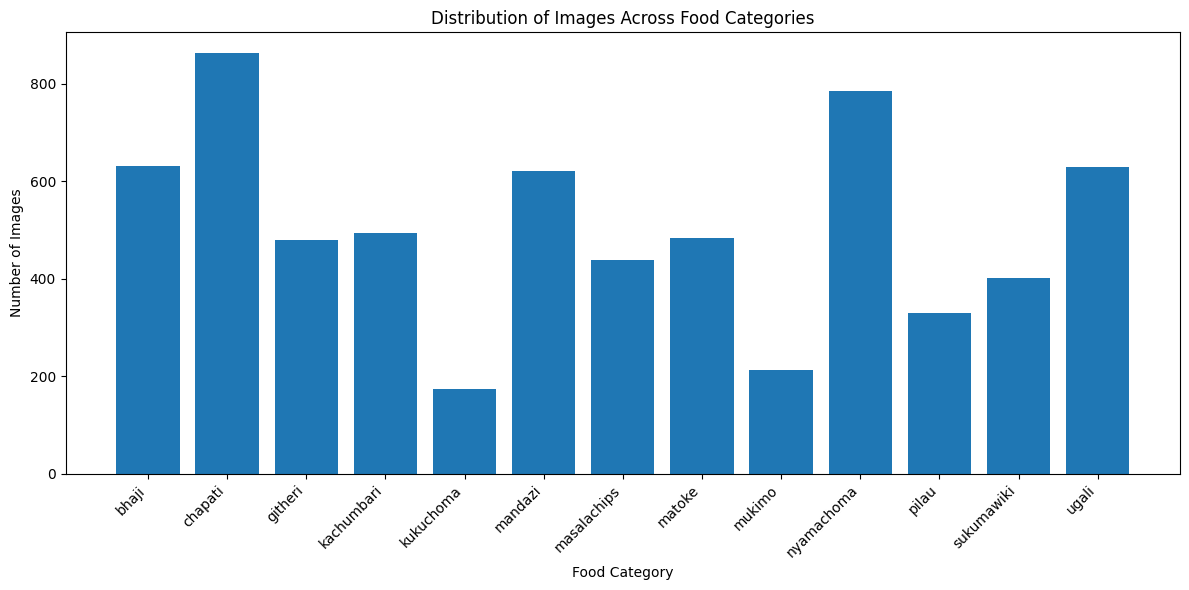

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Original dataset class counts before cleaning
class_counts = {
    "bhaji": 632,
    "chapati": 862,
    "githeri": 479,
    "kachumbari": 494,
    "kukuchoma": 173,
    "mandazi": 620,
    "masalachips": 438,
    "matoke": 483,
    "mukimo": 212,
    "nyamachoma": 784,
    "pilau": 329,
    "sukumawiki": 402,
    "ugali": 628
}

# Create a DataFrame
df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Food Category", "Number of Images"]
)

# Display dataset statistics
print("Total number of images:", df["Number of Images"].sum())
print("Number of food categories:", len(df))

display(df.sort_values(
    by="Number of Images",
    ascending=False
))

# Plot class distribution
plt.figure(figsize=(12, 6))

plt.bar(
    df["Food Category"],
    df["Number of Images"]
)

plt.title("Distribution of Images Across Food Categories")
plt.xlabel("Food Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 2.3 Observations from Exploratory Data Analysis

The exploration of the original dataset revealed the following:

1. The dataset contains 6,536 images across 13 food categories.

2. Chapati has the highest number of images, with 862 samples.

3. Kukuchoma has the lowest number of images, with 173 samples.

4. The dataset has an uneven class distribution. Some categories
   contain significantly more images than others, which may affect
   the model's ability to learn certain food categories.

5. Visual inspection also revealed that some images contain multiple
   food items. This introduces potential ambiguity because each image
   is assigned a single food category.

These observations highlight the importance of cleaning and
preprocessing the dataset before training the classification model.

### 2.4 Visual Inspection of Images

A visual inspection was conducted to understand the appearance
and variation of images within the dataset.

This helps identify differences in food presentation, image quality,
backgrounds and the presence of multiple food items.

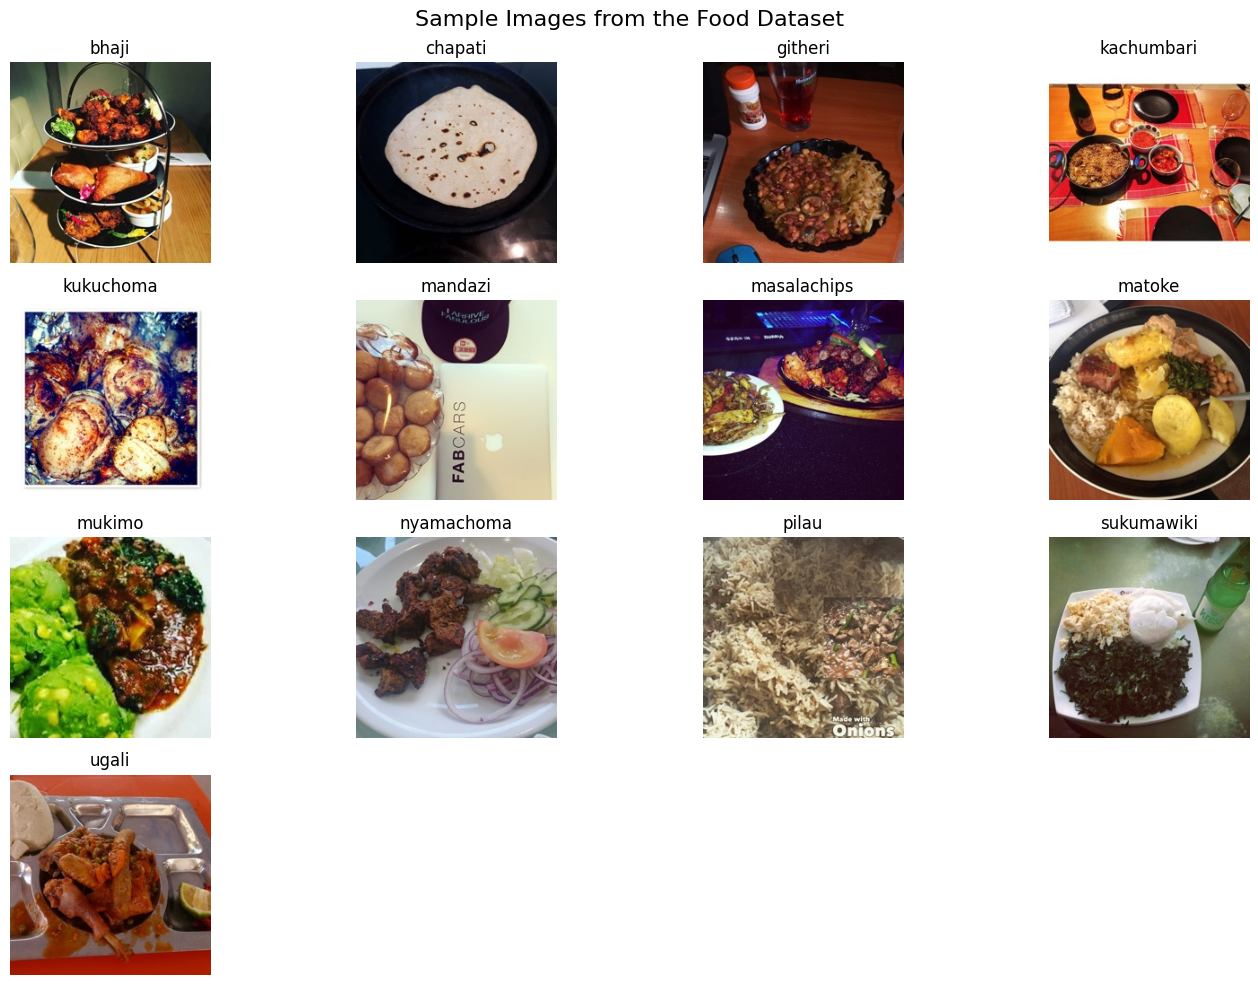

In [1]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

DATASET_DIR = "/content/drive/MyDrive/Food_data/split_dataset/train"

class_names = sorted(os.listdir(DATASET_DIR))

plt.figure(figsize=(14, 10))

for i, class_name in enumerate(class_names):
    class_folder = os.path.join(DATASET_DIR, class_name)

    image_files = [
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_file = random.choice(image_files)
    image_path = os.path.join(class_folder, image_file)

    image = Image.open(image_path)

    plt.subplot(4, 4, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.suptitle("Sample Images from the Food Dataset", fontsize=16)
plt.tight_layout()
plt.show()

# 3. Data Cleaning and Preprocessing

Before training the classification model, the dataset underwent
several cleaning and preprocessing steps to improve data quality
and ensure consistency.

The process involved:

1. Checking for corrupted or unreadable images.
2. Identifying and removing duplicate images.
3. Standardising image formats and dimensions.
4. Splitting the dataset into training, validation and testing sets.

### 3.2 Checking for Corrupted Images

All images were checked to ensure that they could be successfully
opened and processed.

The original dataset contained 6,536 images. The inspection found
that all images were valid, with no corrupted files detected.

Therefore, no images needed to be removed due to corruption.

### 3.3 Duplicate Image Detection

Duplicate images can introduce bias into a machine learning model,
particularly when identical or nearly identical images appear in
different dataset splits.

Perceptual hashing (pHash) was used to identify potential duplicate
images by comparing their visual similarity.

The identified duplicate pairs were manually inspected, and
duplicate copies were removed.

### 3.4 Image Standardisation

The images were standardised before model training.

The following transformations were applied:

- Images were converted to RGB format to ensure consistent colour
  channels.
- Images were resized to 224 × 224 pixels to provide a uniform
  input dimension.
- Images were saved in JPEG format using a quality setting of 95.

A total of 6,462 images were successfully processed, with no
processing failures.

### 3.5 Splitting the Dataset

The cleaned dataset was divided into three subsets:

- Training set: 70% of the data.
- Validation set: 15% of the data.
- Testing set: 15% of the data.

A random seed of 42 was used to ensure reproducibility.

The training set was used to train the CNN, the validation set
was used to monitor model performance during training, and the
testing set was reserved for final evaluation.

In [2]:
import pandas as pd

split_counts = {
    "Training": 4516,
    "Validation": 970,
    "Testing": 976
}

split_df = pd.DataFrame(
    list(split_counts.items()),
    columns=["Dataset Split", "Number of Images"]
)

split_df["Percentage"] = (
    split_df["Number of Images"] / 6462 * 100
).round(2)

display(split_df)

print("Total images:", split_df["Number of Images"].sum())

,Dataset Split,Number of Images,Percentage
0,Training,4516,69.89
1,Validation,970,15.01
2,Testing,976,15.10


Total images: 6462


# 4. Model Development

## 4.1 Model Selection

A Convolutional Neural Network (CNN) was selected for this project
because CNNs are particularly suitable for image classification
tasks.

CNNs automatically learn visual features from images, including
edges, shapes, textures and patterns.

The model was designed to classify food images into 13 predefined
categories using the training dataset.

## 4.2 CNN Architecture

The developed CNN consists of several layers that progressively
extract visual features from the input images.

The architecture includes:

1. Input Layer: Accepts RGB images with dimensions of 224 × 224 × 3.
2. Data Augmentation: Applies random horizontal flipping, rotation
   and zooming to introduce image variation during training.
3. Rescaling: Normalises pixel values to a range between 0 and 1.
4. Convolutional Layers: Extract visual features using 32, 64
   and 128 filters.
5. Batch Normalisation: Helps stabilise and improve training.
6. Max Pooling: Reduces the spatial dimensions of feature maps.
7. Global Average Pooling: Reduces the extracted feature maps
   into a compact representation.
8. Dense Layer: Uses 128 neurons to learn classification patterns.
9. Dropout: Reduces overfitting by randomly disabling some neurons
   during training.
10. Output Layer: Uses 13 neurons with softmax activation to
    generate probabilities for each food category.

## 4.3 Model Implementation

TensorFlow and Keras were used to implement the CNN architecture.

The model was compiled using:

- Optimiser: Adam
- Loss Function: Sparse Categorical Crossentropy
- Evaluation Metric: Accuracy

Sparse Categorical Crossentropy was selected because each image
has a single integer-encoded class label.

In [4]:
import tensorflow as tf

MODEL_PATH = "/content/drive/MyDrive/Food_data/improved_food_cnn.keras"

model = tf.keras.models.load_model(MODEL_PATH)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 13)             │         1,677 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 336,105 (1.28 MB)

 Trainable params: 111,885 (437.05 KB)

 Non-trainable params: 448 (1.75 KB)

 Optimizer params: 223,772 (874.11 KB)

## 4.4 Model Training

The model was trained using the training dataset and evaluated
against the validation dataset after each epoch.

The following training configuration was used:

- Batch size: 32
- Maximum epochs: 15
- Optimiser: Adam
- Early Stopping: Patience of 4 epochs
- Model Checkpoint: Saved the model with the highest validation
  accuracy.

Early stopping was implemented to prevent unnecessary training
when validation performance stopped improving.

The best-performing model was saved for subsequent evaluation.
### 4.4 Model Architecture Summary

The CNN contains three convolutional blocks with 32, 64 and 128
filters respectively. These layers extract increasingly complex
visual features from the input images.

Batch normalisation is applied after each convolutional layer,
followed by max pooling to reduce spatial dimensions.

Global Average Pooling is used instead of flattening to reduce
the number of parameters.

The resulting features are passed through a dense layer containing
128 neurons, followed by a dropout layer with a rate of 0.5.

The final output layer contains 13 neurons and uses softmax
activation to generate class probabilities.

The model contains 112,333 parameters, excluding optimizer
parameters, of which 111,885 are trainable and 448 are
non-trainable.

## 4.5 Training Performance

The training process was monitored using accuracy and loss values
for both the training and validation datasets.

These metrics help assess how effectively the model learned
from the training images and how well it generalised to unseen
validation images.

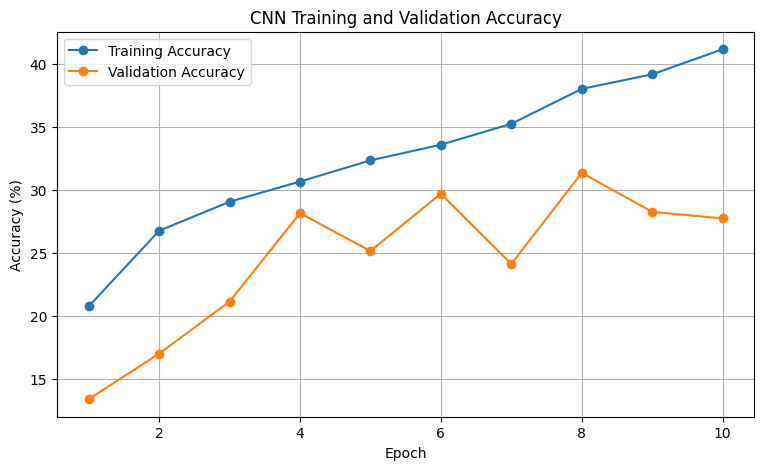

In [5]:
import matplotlib.pyplot as plt

epochs = range(1, 11)

train_accuracy = [
    20.75, 26.75, 29.05, 30.65, 32.33,
    33.57, 35.23, 38.00, 39.15, 41.14
]

val_accuracy = [
    13.40, 17.01, 21.13, 28.14, 25.15,
    29.69, 24.12, 31.34, 28.25, 27.73
]

train_loss = [
    2.7737, 3.1238, 2.7121, 2.2089, 2.3814,
    2.0804, 2.2495, 2.1258, 2.4168, 2.4134
]

# Accuracy graph
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_accuracy, marker='o', label='Training Accuracy')
plt.plot(epochs, val_accuracy, marker='o', label='Validation Accuracy')
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

# 5. Model Evaluation

## 5.1 Introduction

After training the Convolutional Neural Network, its performance
was evaluated using the test dataset.

The test dataset contains images that were not used during model
training or validation.

The following evaluation measures were used:

- Test accuracy
- Test loss
- Precision
- Recall
- F1-score
- Confusion matrix

These measures provide an understanding of the model's overall
performance and its ability to distinguish between the 13 food
categories.

## 5.2 Loading the Trained Model

The best-performing CNN checkpoint was saved during training
based on validation accuracy.

The saved model was loaded to perform the final evaluation
using the independent test dataset.

In [6]:
import tensorflow as tf
import os

from google.colab import drive
drive.mount('/content/drive')

DATASET_DIR = "/content/drive/MyDrive/Food_data/split_dataset"
MODEL_PATH = "/content/drive/MyDrive/Food_data/improved_food_cnn.keras"

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# Load test dataset
test_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "test"),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Load trained model
best_model = tf.keras.models.load_model(MODEL_PATH)

class_names = test_dataset.class_names

print("Number of classes:", len(class_names))
print("Food categories:", class_names)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found 976 files belonging to 13 classes.
Number of classes: 13
Food categories: ['bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalachips', 'matoke', 'mukimo', 'nyamachoma', 'pilau', 'sukumawiki', 'ugali']


## 5.3 Test Accuracy and Loss

Test accuracy measures the proportion of test images that were
correctly classified by the model.

Test loss measures the difference between the model's predicted
probabilities and the actual class labels.

The trained CNN achieved a test accuracy of 34.22% and a test
loss of 2.0595.

In [7]:
test_loss, test_accuracy = best_model.evaluate(test_dataset)

print("Final Test Results")
print("------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

31/31 ━━━━━━━━━━━━━━━━━━━━ 469s 15s/step - accuracy: 0.3422 - loss: 2.0595
Final Test Results
------------------
Test Loss: 2.0595
Test Accuracy: 34.22%


## 5.4 Classification Report

A classification report was generated to evaluate the model's
performance across individual food categories.

The report includes:

- Precision: The proportion of predictions for a category
  that were correct.
- Recall: The proportion of actual images in a category
  correctly identified.
- F1-score: The harmonic mean of precision and recall.
- Support: The number of test images belonging to each category.

This provides a more detailed assessment than accuracy alone.

In [8]:
import numpy as np
from sklearn.metrics import classification_report

# Actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

# Model predictions
y_prob = best_model.predict(test_dataset)
y_pred = np.argmax(y_prob, axis=1)

# Generate classification report
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

31/31 ━━━━━━━━━━━━━━━━━━━━ 5s 135ms/step
              precision    recall  f1-score   support

       bhaji       0.25      0.11      0.15        95
     chapati       0.90      0.21      0.34       129
     githeri       0.26      0.31      0.28        72
  kachumbari       0.36      0.34      0.35        73
   kukuchoma       0.00      0.00      0.00        26
     mandazi       0.49      0.71      0.58        93
 masalachips       0.32      0.27      0.29        66
      matoke       0.33      0.32      0.32        73
      mukimo       0.43      0.19      0.26        32
  nyamachoma       0.25      0.88      0.40       118
       pilau       0.71      0.11      0.19        45
  sukumawiki       0.50      0.08      0.14        60
       ugali       0.43      0.24      0.31        94

    accuracy                           0.34       976
   macro avg       0.40      0.29      0.28       976
weighted avg       0.43      0.34      0.31       976



## 5.5 Confusion Matrix

A confusion matrix was used to examine the relationship
between actual food categories and the categories predicted
by the model.

The rows represent the actual food categories, while the
columns represent the predicted categories.

Correct predictions appear along the diagonal of the matrix.
Values outside the diagonal represent incorrect classifications.

This helps identify which food categories the model struggles
to distinguish.

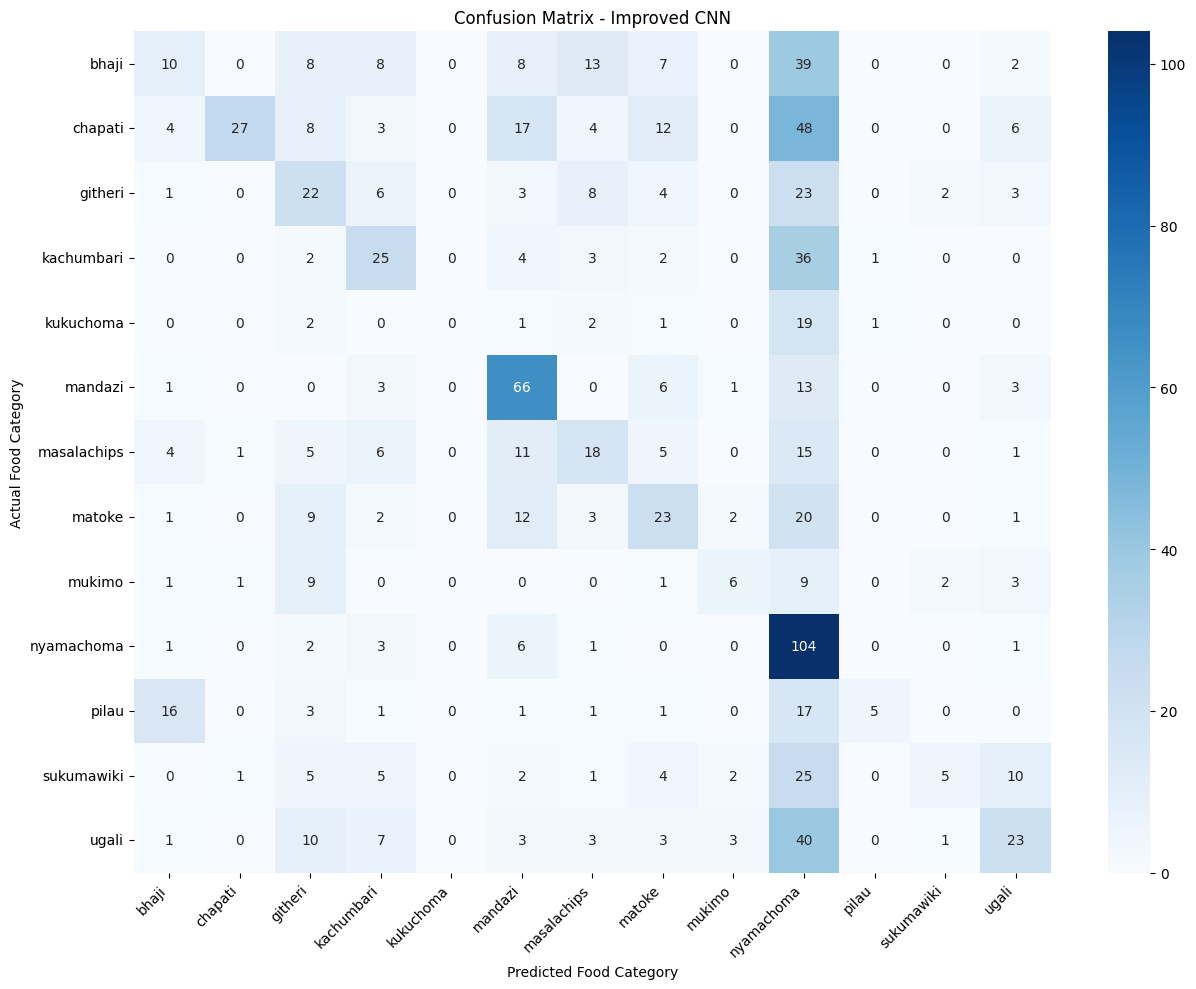

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Improved CNN")
plt.xlabel("Predicted Food Category")
plt.ylabel("Actual Food Category")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## 5.6 Interpretation of Results

The improved CNN achieved a test accuracy of 34.22% on the
976 test images.

The classification report revealed differences in performance
across the 13 food categories.

Mandazi achieved the highest F1-score of 0.58, indicating
relatively better classification performance.

Nyama Choma achieved a recall of 0.88, meaning that the model
identified most of the actual Nyama Choma images. However,
its precision was only 0.25, indicating a high number of
incorrect predictions.

Kukuchoma had an F1-score of 0.00, showing that the model
failed to correctly identify any images in that category.

The confusion matrix also revealed considerable confusion
between different food categories.

One possible contributing factor is that some dataset images
contain multiple food items, despite being assigned a single
category. This can introduce ambiguity during supervised
learning.

Overall, the model demonstrated an ability to recognise
certain food categories, but its classification performance
indicates opportunities for improvement.

# 6. Conclusion and Recommendations

## 6.1 Conclusion

This project involved the development of a supervised machine
learning model for classifying images of Kenyan food into
13 different categories.

A Convolutional Neural Network (CNN) was developed using
TensorFlow and Keras.

The dataset initially contained 6,536 images. Following cleaning
and preprocessing, 6,462 images were retained and divided into
training, validation and testing datasets.

The improved CNN achieved a test accuracy of 34.22% and a
test loss of 2.0595.

The evaluation demonstrated that the model could recognise
certain food categories more effectively than others.
Mandazi achieved the highest F1-score of 0.58, while
Kukuchoma had an F1-score of 0.00.

Although the model demonstrated the ability to learn visual
patterns from food images, its overall classification
performance indicates that further improvements are necessary.

The project successfully demonstrated the application of
computer vision and supervised learning to Kenyan food
image classification.

## 6.2 Project Limitations

Several limitations affected the performance of the model:

1. Dataset ambiguity:
   Some images contained multiple food items despite having
   only one assigned category. This introduced ambiguity
   during training.

2. Class imbalance:
   The dataset contained unequal numbers of images across
   the 13 categories. Some categories had considerably
   fewer training examples than others.

3. Visual similarities:
   Certain Kenyan foods share similar colours, textures
   and appearances, making them difficult to distinguish.

4. Limited model performance:
   The final model achieved a test accuracy of 34.22%,
   indicating that its ability to generalise across all
   food categories remains limited.

5. Model comparison:
   Due to time constraints, the improved CNN was evaluated
   without completing a comparison against alternative
   architectures such as transfer-learning models.

## 6.3 Recommendations for Future Improvement

The following improvements could be considered in future
iterations of the project:

1. Dataset improvement:
   Review and refine the dataset by removing ambiguous
   images and correcting incorrectly labelled samples.

2. Class balancing:
   Apply data augmentation or class-weighting techniques
   to improve learning across underrepresented categories.

3. Transfer learning:
   Experiment with pretrained architectures such as
   MobileNetV2 or EfficientNet to potentially improve
   classification performance.

4. Model optimisation:
   Experiment with different hyperparameters,
   convolutional architectures and regularisation methods.

5. Model comparison:
   Evaluate multiple classification models using the same
   dataset and evaluation metrics to determine which
   architecture performs best.

These improvements could help produce a more accurate
and reliable Kenyan food classification system.

## 6.4 Final Summary

The project successfully implemented a CNN-based approach
to classifying 13 categories of Kenyan food images.

The final model achieved 34.22% accuracy on the independent
test dataset.

Despite its limitations, the project provided practical
experience in dataset exploration, image preprocessing,
CNN development and model evaluation.

Further improvements to dataset quality and model
architecture could enhance the performance of the system.